# Setup

This notebook builds an 8-bit animation of Badshahi Masjid, Lahore, from nothing: first single pixels, then lines,
shapes and a still picture, then time, motion and physics. Nothing is drawn by hand. Every part of the picture is
computed from a few numbers, so it can be changed, repeated and animated.

Libraries: **numpy** holds the picture as an array of numbers and does arithmetic on all pixels at once;
**matplotlib** shows pictures in the notebook; **Pillow** saves images and animated GIFs. All three come with Colab
and Anaconda.

In [1]:
import math
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

OUT = Path("data")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})
print("numpy", np.__version__)

numpy 2.0.1


# A picture is a grid of numbers

A screen is a grid of small squares called **pixels**. Our canvas is 160 pixels wide and 120 high, about the size of
a 1980s home computer screen. Position is given by a column **x** (0 at the left) and a row **y** (0 at the
**top**: on screens y grows downwards, the opposite of a graph in maths).

Old machines did not store a colour for each pixel. They stored a small number, an index into a **palette** of 16
colours, so a pixel needed half a byte instead of three. We do the same: the canvas holds numbers 0 to 15, and the
palette turns each into red, green and blue amounts (0 to 255 each). Changing one palette entry recolours every
pixel that uses it at once, a trick we use later for night.

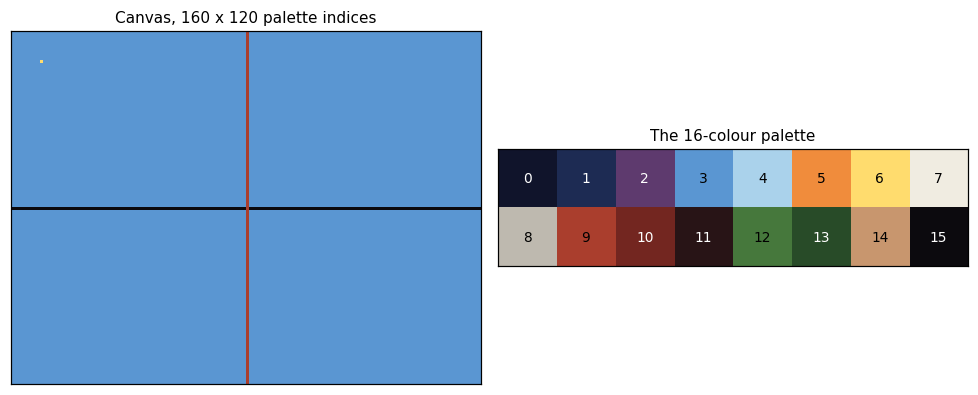

canvas shape (rows, columns): (120, 160)  bytes: 19200  value at row 60, column 5: 15


In [2]:
W, H = 160, 120
GROUND = 104
PALETTE = [
    (16, 20, 43), (29, 43, 83), (94, 58, 110), (90, 150, 210),      # 0 night, 1 deep blue, 2 dusk, 3 day sky
    (170, 210, 235), (240, 140, 60), (255, 220, 110), (240, 236, 225),  # 4 pale sky, 5 orange, 6 sun, 7 marble
    (190, 185, 175), (170, 62, 45), (115, 38, 32), (40, 20, 22),    # 8 marble shade, 9 sandstone, 10 its shade, 11 door
    (70, 120, 60), (40, 75, 40), (200, 150, 110), (12, 10, 14),     # 12 lawn, 13 lawn shade, 14 path, 15 black
]
RGB = np.array(PALETTE, dtype=np.uint8)


def new_canvas(colour=0):
    return np.full((H, W), colour, dtype=np.uint8)


def put_pixel(c, x, y, col):
    """Set one pixel, ignoring positions off the canvas (a 'clipped' write)."""
    if 0 <= x < W and 0 <= y < H:
        c[int(y), int(x)] = col


def show(c, title=None, ax=None):
    ax = ax or plt.figure(figsize=(6, 4.5)).gca()
    ax.imshow(RGB[c], interpolation="nearest")          # RGB[c] looks every index up in the palette at once
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)


c = new_canvas(3)
for x in range(W):
    put_pixel(c, x, 60, 15)          # a horizontal row of black pixels at y = 60
for y in range(H):
    put_pixel(c, 80, y, 9)           # a vertical column of red pixels at x = 80
put_pixel(c, 10, 10, 6)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
show(c, "Canvas, 160 x 120 palette indices", axes[0])
axes[1].imshow(RGB[np.arange(16).reshape(2, 8)], interpolation="nearest")
for i in range(16):
    axes[1].text(i % 8, i // 8, str(i), ha="center", va="center", fontsize=9, color="white" if i in (0, 1, 2, 10, 11, 13, 15) else "black")
axes[1].set_xticks([]); axes[1].set_yticks([]); axes[1].set_title("The 16-colour palette", fontsize=10)
plt.tight_layout(); plt.show()
print("canvas shape (rows, columns):", c.shape, " bytes:", c.nbytes, " value at row 60, column 5:", c[60, 5])

The left panel is the canvas: one black row, one red column and a single yellow pixel near the top left, at
x = 10, y = 10. The right panel shows the palette with each index printed on its colour. The printout confirms
that the whole picture is 19,200 bytes (one byte per pixel; a real 8-bit machine would pack two pixels per byte) and that
the pixel at row 60, column 5 holds 15, the index of black. Note that numpy indexes **row first**: `c[y, x]`.

# Lines and circles from scratch

A line from (x0, y0) to (x1, y1) must be drawn as a staircase of whole pixels. The obvious way, computing
y = y0 + slope × (x − x0) for each x, leaves gaps when the line is steep and needs fractions. **Bresenham's
algorithm** (1965) uses only whole numbers: it walks one pixel at a time and keeps a running **error**, how far the
true line has drifted from the pixel centre, and steps sideways whenever the error passes half a pixel. This is
what `line()` in the old `graphics.h` library and every early games machine did.

A circle uses the same idea. The **midpoint circle algorithm** works out one eighth of the circle and copies each
point to the other seven by symmetry: if (x, y) is on a circle about the centre, so are (y, x), (−x, y) and so on.

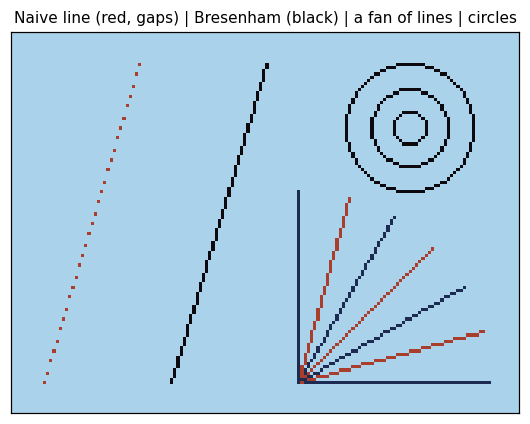

pixels lit by the naive steep line: 31 for a rise of 100 rows


In [3]:
def line(c, x0, y0, x1, y1, col):
    x0, y0, x1, y1 = int(round(x0)), int(round(y0)), int(round(x1)), int(round(y1))
    dx, dy = abs(x1 - x0), -abs(y1 - y0)
    sx, sy = (1 if x0 < x1 else -1), (1 if y0 < y1 else -1)
    err = dx + dy                                   # error term, scaled to stay a whole number
    while True:
        put_pixel(c, x0, y0, col)
        if x0 == x1 and y0 == y1:
            return
        e2 = 2 * err
        if e2 >= dy:                                # the line has moved far enough to step in x
            err += dy; x0 += sx
        if e2 <= dx:                                # and/or in y
            err += dx; y0 += sy


def circle(c, cx, cy, r, col):
    x, y, err = r, 0, 1 - r
    while x >= y:
        for px, py in ((x, y), (y, x), (-y, x), (-x, y), (-x, -y), (-y, -x), (y, -x), (x, -y)):
            put_pixel(c, cx + px, cy + py, col)
        y += 1
        if err < 0:
            err += 2 * y + 1                         # midpoint inside the circle: keep x
        else:
            x -= 1; err += 2 * (y - x) + 1           # outside: step x inwards


def naive_line(c, x0, y0, x1, y1, col):
    for x in range(x0, x1 + 1):
        put_pixel(c, x, round(y0 + (y1 - y0) / (x1 - x0) * (x - x0)), col)


c = new_canvas(4)
naive_line(c, 10, 110, 40, 10, 9)                 # steep: gaps appear
line(c, 50, 110, 80, 10, 15)                      # Bresenham: unbroken
for i, a in enumerate(np.linspace(0, math.pi / 2, 7)):
    line(c, 90, 110, 90 + 60 * math.cos(a), 110 - 60 * math.sin(a), 1 + i % 2 * 8)
for r in (5, 12, 20):
    circle(c, 125, 30, r, 15)
show(c, "Naive line (red, gaps) | Bresenham (black) | a fan of lines | circles")
plt.show()
lit = int((c == 9).sum())
print("pixels lit by the naive steep line:", (c[:, :45] == 9).sum(), "for a rise of 100 rows")

The red line on the left was drawn the naive way. It is steep (100 rows for 30 columns), and the loop visits each
column once, so it lights only 31 pixels for 100 rows and is full of gaps; the printout confirms the count.
Bresenham's black line beside it steps in whichever direction the line moves faster and is unbroken. The fan shows
lines at seven angles, all unbroken; the circles at the top right are drawn from one eighth of their outline each.

# Shapes as inside tests

Outlines are not enough; a mosque is made of filled shapes. The easiest way to fill a shape is to ask, for every
pixel, **is this pixel inside?** A shape then becomes a **mask**: an array of True and False the size of the
canvas, and filling it is one line, `c[mask] = colour`. numpy computes the test for all 19,200 pixels at once from
two arrays holding every pixel's column `X` and row `Y`.

- A **rectangle** is x0 ≤ x < x1 and y0 ≤ y < y1.
- A **disc** (filled circle) of radius r is (x − cx)² + (y − cy)² ≤ r².
- A **Mughal pointed arch** is the overlap of two discs. Put the centres a distance *k·w/2* either side of the
  arch's middle line, with radius *w/2 + k·w/2*, so each circle passes through the far springing point (where the
  arch leaves its vertical sides). With *k* = 0 both centres coincide and the arch is round; with *k* = 1 it is the
  steep 'equilateral' arch. Badshahi Masjid's arches are close to *k* = 0.5.
- An **onion dome** has a width that changes with height. Let *u* run from 0 at the base to 1 at the tip. The half
  width is *R*(1 − *u*)^0.7 (1 + 1.2*u*): the second factor swells the dome outwards, the first pulls it to a point,
  and the product is widest about a third of the way up. A third factor narrows the very bottom into a neck.

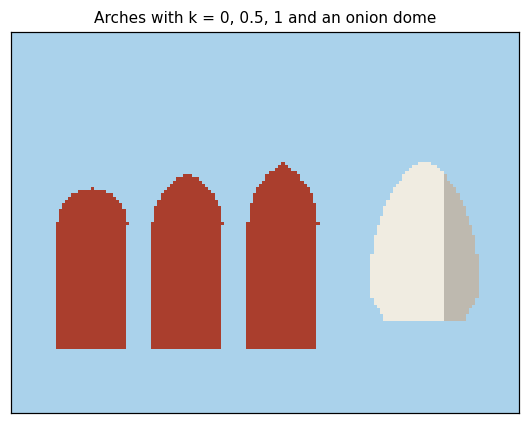

u      :  0.0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  0.9  1.0
width/R: 0.80 0.97 1.06 1.06 1.04 0.98 0.91 0.79 0.64 0.42 0.00
widest at u = 0.2 where the dome is 1.06 times its base radius


In [4]:
Y, X = np.mgrid[0:H, 0:W]          # Y[row, col] = row, X[row, col] = col


def fill(c, mask, col):
    c[mask] = col


def rect(x0, y0, x1, y1):
    return (X >= x0) & (X < x1) & (Y >= y0) & (Y < y1)


def disc(cx, cy, r):
    return (X - cx) ** 2 + (Y - cy) ** 2 <= r * r


def pointed_arch(cx, spring, bottom, w, k=0.5):
    off = k * w / 2
    r = w / 2 + off
    top = disc(cx + off, spring, r) & disc(cx - off, spring, r) & (Y <= spring)
    return top | rect(cx - w / 2, spring, cx + w / 2, bottom)


def onion(cx, base, R, h):
    u = (base - Y) / h
    hw = R * np.clip(1 - u, 0, 1) ** 0.7 * (1 + 1.2 * u) * (0.8 + 0.2 * np.clip(u / 0.15, 0, 1))
    return (u >= 0) & (u <= 1) & (np.abs(X - cx + 0.5) <= hw)


c = new_canvas(4)
for i, k in enumerate((0.0, 0.5, 1.0)):
    fill(c, pointed_arch(25 + 30 * i, 60, 100, 22, k), 9)
fill(c, onion(130, 90, 16, 50), 7)
fill(c, onion(130, 90, 16, 50) & (X > 135), 8)
show(c, "Arches with k = 0, 0.5, 1 and an onion dome")
plt.show()

u = np.linspace(0, 1, 11)
hw = (1 - u) ** 0.7 * (1 + 1.2 * u) * (0.8 + 0.2 * np.clip(u / 0.15, 0, 1))
print("u      :", " ".join(f"{v:4.1f}" for v in u))
print("width/R:", " ".join(f"{v:4.2f}" for v in hw))
print("widest at u =", u[hw.argmax()], "where the dome is", round(hw.max(), 2), "times its base radius")

The three red arches share one formula and differ only in *k*: round, Mughal and steeply pointed. The white dome
is shaded on its right, where a second mask (the dome **and** x > 135) is filled with the shade colour: light comes
from the left. The table gives the dome's half width as a multiple of *R* at eleven heights. It starts at 0.8
(the neck), peaks at 1.1 times *R* at *u* = 0.2 and falls to 0 at the tip, which is the onion shape. To change the
dome, change the exponent or the 1.2 and run the cell again.

# Dithering and the 8-bit look

A sky fades from deep blue overhead to pale at the horizon, but we have only 16 colours. **Ordered dithering**
mixes two colours in a fixed pattern, so that from a distance the eye averages them. Each pixel gets a threshold
from a 4 × 4 **Bayer matrix**, a table of the numbers 0 to 15 arranged so that neighbouring thresholds are far
apart. Where the wanted mix (0 = all top colour, 1 = all bottom colour) exceeds the pixel's threshold, the pixel
takes the bottom colour. Halfway down, half the pixels in every 4 × 4 block take each colour, in a checkerboard.

Bayer thresholds (x 16):
 [[ 0  8  2 10]
 [12  4 14  6]
 [ 3 11  1  9]
 [15  7 13  5]]
rows 8-11: share of pale pixels = 0.125  (wanted 0.091)
rows 52-55: share of pale pixels = 0.500  (wanted 0.514)
rows 92-95: share of pale pixels = 0.938  (wanted 0.899)


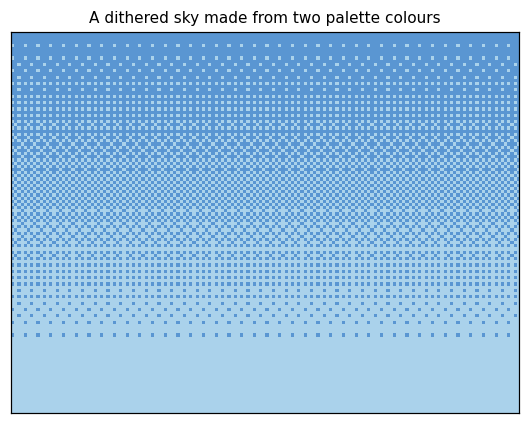

In [5]:
BAYER = np.array([[0, 8, 2, 10], [12, 4, 14, 6], [3, 11, 1, 9], [15, 7, 13, 5]]) / 16


def gradient(c, top, bottom, y_end=GROUND):
    t = Y / y_end                                             # 0 at the top, 1 at y_end
    c[:] = np.where(t > BAYER[Y % 4, X % 4], bottom, top)


c = new_canvas()
gradient(c, 3, 4)
print("Bayer thresholds (x 16):\n", (BAYER * 16).astype(int))
for row in (8, 52, 92):                                    # a band of 4 rows uses all 16 thresholds once
    band = c[row:row + 4]
    print(f"rows {row}-{row + 3}: share of pale pixels = {(band == 4).mean():.3f}  (wanted {(row + 1.5) / GROUND:.3f})")
show(c, "A dithered sky made from two palette colours"); plt.show()

The printout checks the method on bands of four rows, since a band of four rows meets each of the 16 thresholds
once. Near the top (rows 8 to 11) 9 % of pixels should be pale and 12.5 % (2 of 16) are; in the middle (rows 52 to
55) half should be and exactly half are; near the horizon (rows 92 to 95) 90 % should be and 94 % (15 of 16) are.
A 4 × 4 matrix can only make 17 levels, 0/16 to 16/16, so each band gets one of the levels nearest what was wanted. The picture shows
the pattern: no new colour is used, yet the sky looks graded.

# Components: a mosque from parts

Badshahi Masjid (1673) has a few kinds of parts, each repeated: **minarets** (towers with white bands, balconies
and a small domed pavilion, a *chhatri*, on top), **domes** on round **drums**, **walls** of red sandstone with a
row of merlons along the top, and **pointed arches** framed in white marble. We write each kind once as a
**class**: a recipe holding a few numbers (position and size) and a `draw` method that turns them into pixels. A
particular minaret is an **object**, one use of the recipe.

The building is symmetric about its centre line, so we describe only the left half and **mirror** each part:
x becomes W − x. The whole building is then a list of objects, drawn back to front so that nearer parts cover
farther ones (the 'painter's algorithm'). This list is data: you could save it as a table, edit it, or generate it.

Minaret(x=14, top=24, w=7, bottom=96, balconies=(0.25, 0.5, 0.75))
Minaret(x=146, top=24, w=7, bottom=96, balconies=(0.25, 0.5, 0.75))
Dome(cx=46, base=52, R=9, h=16, drum=6)
Dome(cx=114, base=52, R=9, h=16, drum=6)
Dome(cx=80, base=38, R=13, h=22, drum=6)
Block(x0=30, y0=60, x1=66, y1=96)
... 16 components in all


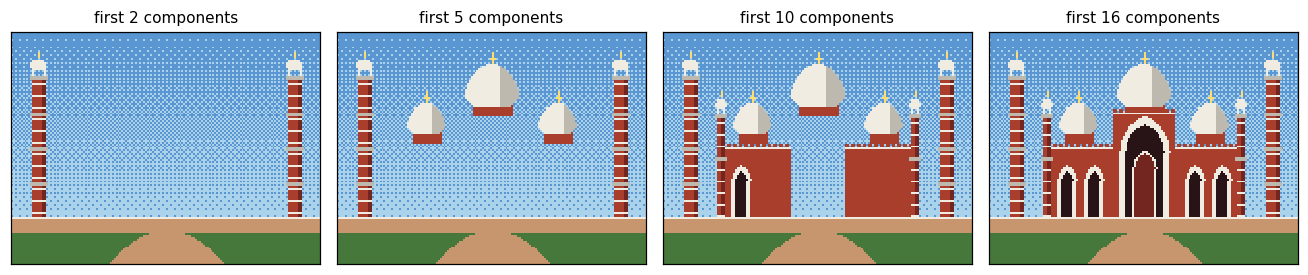

In [6]:
@dataclass
class Dome:
    cx: float; base: float; R: float; h: float; drum: float = 6

    def draw(self, c):
        fill(c, rect(self.cx - self.R * 0.8, self.base, self.cx + self.R * 0.8, self.base + self.drum), 9)
        m = onion(self.cx, self.base, self.R, self.h)
        fill(c, m, 7)
        fill(c, m & (X > self.cx + self.R * 0.3), 8)
        top = self.base - self.h
        line(c, self.cx, top, self.cx, top - 5, 6)          # gilded finial: a spire with a ball
        fill(c, disc(self.cx, top - 2, 1.2), 6)


@dataclass
class Minaret:
    x: float; top: float; w: float = 6; bottom: float = GROUND - 8; balconies: tuple = (0.3, 0.6)

    def draw(self, c):
        x0, x1 = self.x - self.w / 2, self.x + self.w / 2
        fill(c, rect(x0, self.top, x1, self.bottom), 9)
        fill(c, rect(x1 - 2, self.top, x1, self.bottom), 10)
        for yy in range(int(self.top) + 3, int(self.bottom), 6):
            fill(c, rect(x0, yy, x1, yy + 1), 7)
        for f in self.balconies:
            yy = self.top + f * (self.bottom - self.top)
            fill(c, rect(x0 - 1, yy, x1 + 1, yy + 2), 8)
        fill(c, rect(x0 - 1, self.top - 1, x1 + 1, self.top + 1), 8)
        for px in (x0, x1 - 1):
            fill(c, rect(px, self.top - 5, px + 1, self.top - 1), 7)
        fill(c, onion(self.x, self.top - 5, self.w / 2 + 0.5, 5), 7)
        line(c, self.x, self.top - 11, self.x, self.top - 13, 6)


@dataclass
class Arch:
    cx: float; spring: float; bottom: float; w: float; frame: float = 2; k: float = 0.5; inner: int = 11

    def draw(self, c):
        fill(c, pointed_arch(self.cx, self.spring, self.bottom, self.w + 2 * self.frame, self.k), 7)
        fill(c, pointed_arch(self.cx, self.spring, self.bottom, self.w, self.k), self.inner)


@dataclass
class Block:
    x0: float; y0: float; x1: float; y1: float

    def draw(self, c):
        fill(c, rect(self.x0, self.y0, self.x1, self.y1), 9)
        fill(c, rect(self.x0, self.y0, self.x1, self.y0 + 1), 7)
        for xx in range(int(self.x0), int(self.x1), 3):
            fill(c, rect(xx, self.y0 - 2, xx + 2, self.y0), 9)


def mirror(comp):
    d = dict(comp.__dict__)
    key = "cx" if "cx" in d else "x" if "x" in d else None
    if key:
        d[key] = W - d[key]
    else:
        d["x0"], d["x1"] = W - d["x1"], W - d["x0"]
    return type(comp)(**d)


def badshahi():
    left = [Minaret(14, 24, 7, balconies=(0.25, 0.5, 0.75)), Dome(46, 52, 9, 16), Block(30, 60, 66, GROUND - 8),
            Minaret(30, 44, 4, balconies=(0.4,)), Arch(40, 76, GROUND - 8, 6), Arch(54, 76, GROUND - 8, 6)]
    centre = [Dome(80, 38, 13, 22), Block(64, 42, 96, GROUND - 8),
              Arch(80, 62, GROUND - 8, 20, frame=3), Arch(80, 70, GROUND - 8, 10, frame=1, inner=10)]
    comps = []
    for comp in left:
        comps += [comp, mirror(comp)]
    return comps[:4] + centre[:1] + comps[4:] + centre[1:]


def ground(c):
    fill(c, rect(0, GROUND - 8, W, GROUND), 14)
    fill(c, rect(0, GROUND - 8, W, GROUND - 7), 7)
    fill(c, Y >= GROUND, 12)
    fill(c, (Y >= GROUND) & ((X - 80) ** 2 * 0.02 < (Y - GROUND + 2)), 14)


scene = badshahi()
for comp in scene[:6]:
    print(comp)
print("...", len(scene), "components in all")

fig, axes = plt.subplots(1, 4, figsize=(12, 2.6))
c = new_canvas(); gradient(c, 3, 4); ground(c)
for i, n in enumerate((2, 5, 10, len(scene))):
    step = c.copy()
    for comp in scene[:n]:
        comp.draw(step)
    show(step, f"first {n} components", axes[i])
plt.tight_layout(); plt.show()
still = step
Image.fromarray(RGB[still]).resize((W * 4, H * 4), Image.NEAREST).save(OUT / "badshahi_still.png")

The printout lists the first six objects: each is just a name and a few numbers, and mirrored pairs differ only
in their x (14 and 146, 46 and 114). The four panels draw the list in order. After 2 components the two great
minarets stand alone; after 5 the side domes and the central dome are up; after 10 the walls cover the bases of
the domes, as the painter's algorithm intends; the last panel is the whole front, 16 components from 6 written by
hand. The still is saved as `data/badshahi_still.png`, scaled up four times with **nearest-neighbour** resampling
so the pixels stay sharp squares.

# Time and frames

An animation is a sequence of still pictures, **frames**, shown quickly; at 20 frames a second the eye sees motion.
A program makes them with a loop: for each frame, work out the time *t*, update everything that moves, draw the
scene, and store the picture. Everything that changes is a **function of time**.

**The sun** moves on a circle of radius 84 centred below the ground. A day is one turn, *phase* 0 to 1: the angle is
*a* = 2π × phase, the position is (80 − 84 cos *a*, 104 − 84 sin *a*), and sin *a* is the sun's **elevation**: positive
by day, negative by night. The sky's two colours are chosen from the elevation.

**Night** uses the palette trick: every colour of the building is swapped for its darker partner (sandstone 9
becomes shade 10, marble 7 becomes grey 8). This is a **palette swap**, as old games did to make night levels
without drawing anything again.

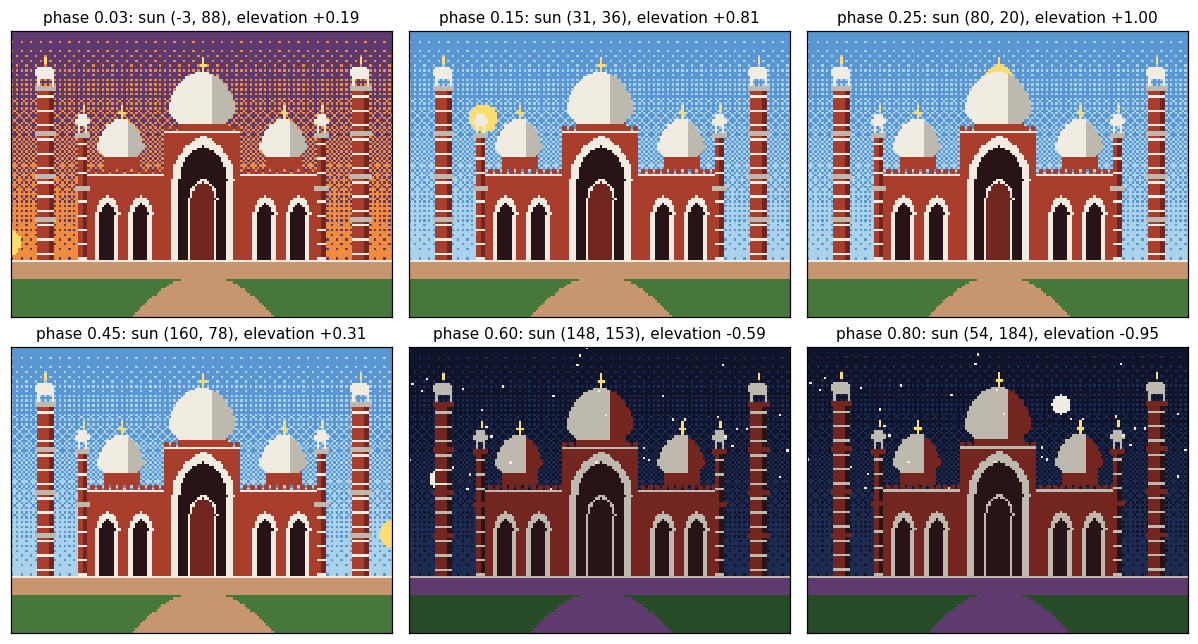

saved data\day_and_night.gif


In [7]:
NIGHT = {9: 10, 7: 8, 12: 13, 14: 2, 8: 10, 10: 11}


def sun_position(phase):
    a = 2 * math.pi * phase
    return 80 - 84 * math.cos(a), GROUND - 84 * math.sin(a), math.sin(a)


def sky(c, elevation):
    if elevation > 0.25:   top, bottom = 3, 4      # day
    elif elevation > 0:    top, bottom = 2, 5      # sunrise and sunset glow
    elif elevation > -0.2: top, bottom = 0, 2      # twilight
    else:                  top, bottom = 0, 1      # night
    gradient(c, top, bottom)
    if elevation < 0:
        rng = np.random.default_rng(7)             # same seed, so the same stars every frame
        c[rng.integers(0, 60, 40), rng.integers(0, W, 40)] = 7


def render(phase, extras=()):
    c = new_canvas()
    sx, sy, elev = sun_position(phase)
    sky(c, elev)
    if elev > -0.05:
        fill(c, disc(sx, sy, 6), 6)
    else:
        mx, my, _ = sun_position(phase + 0.5)       # the moon is opposite the sun
        fill(c, disc(mx, my, 4), 7)
    ground(c)
    before = c.copy()
    for comp in badshahi():
        comp.draw(c)
    if elev < 0:
        covered = (c != before) | (Y >= GROUND - 8)
        old = c.copy()
        for a, b in NIGHT.items():
            c[covered & (old == a)] = b
    for e in extras:
        e(c)
    return c


phases = [0.03, 0.15, 0.25, 0.45, 0.6, 0.8]
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, p in zip(axes.flat, phases):
    sx, sy, e = sun_position(p)
    show(render(p), f"phase {p:.2f}: sun ({sx:.0f}, {sy:.0f}), elevation {e:+.2f}", ax)
plt.tight_layout(); plt.show()


def save_gif(frames, path, fps=20):
    imgs = [Image.fromarray(RGB[f]).resize((W * 4, H * 4), Image.NEAREST) for f in frames]
    imgs[0].save(path, save_all=True, append_images=imgs[1:], duration=int(1000 / fps), loop=0)


save_gif([render(-0.05 + 1.1 * f / 120) for f in range(120)], OUT / "day_and_night.gif", fps=15)
print("saved", OUT / "day_and_night.gif")

Each panel is the same scene at a different phase of the day; only the phase number changed. At phase 0.03 the sun
has just risen at the left (elevation +0.19), so the sky has the sunrise glow. At 0.15 and 0.25 it is high and the
sky is blue. At 0.45 it is setting on the right. At 0.6 and 0.8 the elevation is negative: the sky turns dark, stars
appear, the moon is up, and the building has swapped to its night colours. The 120 frames are saved as an animated
GIF in `data/`; open it to watch a whole day in eight seconds.

# Physics: forces and integration

Natural motion comes from **Newton's second law**: the acceleration of a body is the total **force** on it divided by
its **mass**, *a* = *F*/*m*. A computer cannot solve this continuously, so it takes small time steps *Δt* and updates
velocity and position in turn. This is **numerical integration**. The simplest rule, **explicit Euler**, moves the
position with the old velocity:

*x* ← *x* + *v* Δt,  *v* ← *v* + *a* Δt.

**Semi-implicit (symplectic) Euler** updates the velocity first and moves with the new velocity:

*v* ← *v* + *a* Δt,  *x* ← *x* + *v* Δt.

The change looks trivial, but it matters. Test both on a spring, where the exact answer is known: a mass on a spring
of stiffness *k* swings for ever with constant energy ½*kx*² + ½*mv*². A good method keeps that energy constant.

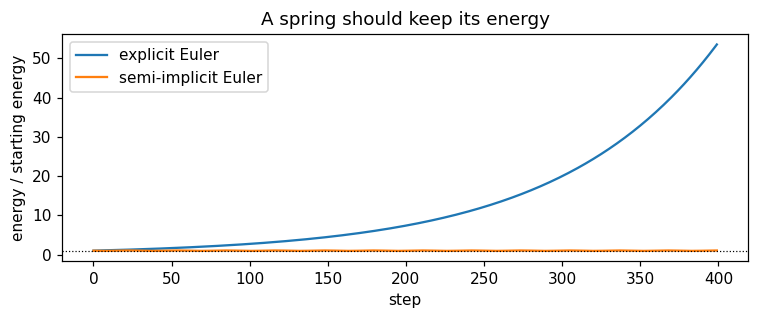

after 400 steps (20 s): explicit 53.52 x start, semi-implicit 1.05 x start (range 0.95 to 1.05)


In [8]:
def spring_energy(method, dt=0.05, steps=400, k=4.0, m=1.0):
    x, v = 1.0, 0.0
    E = []
    for _ in range(steps):
        a = -k * x / m
        if method == "explicit":
            x, v = x + v * dt, v + a * dt
        else:
            v = v + a * dt
            x = x + v * dt
        E.append(0.5 * k * x * x + 0.5 * m * v * v)
    return np.array(E)


E0 = 0.5 * 4.0 * 1.0 ** 2
ex, si = spring_energy("explicit"), spring_energy("semi")
plt.figure(figsize=(7, 3))
plt.plot(ex / E0, label="explicit Euler"); plt.plot(si / E0, label="semi-implicit Euler")
plt.axhline(1, color="k", lw=0.8, ls=":"); plt.xlabel("step"); plt.ylabel("energy / starting energy")
plt.legend(); plt.title("A spring should keep its energy"); plt.tight_layout(); plt.show()
print(f"after 400 steps (20 s): explicit {ex[-1] / E0:.2f} x start, semi-implicit {si[-1] / E0:.2f} x start "
      f"(range {si.min() / E0:.2f} to {si.max() / E0:.2f})")

The dotted line is the truth: energy stays at 1. Explicit Euler (blue) gains energy every step and has grown about
fifty-fold after 20 seconds, so a spring drawn with it would fling itself off the screen. Semi-implicit Euler (orange) wobbles a
little around 1 but never drifts, so it can run for ever. We use it for everything that moves.

**The kite.** Basant, the spring kite festival, filled Lahore's sky with kites. Ours is a point mass held by a
string from a rooftop at the lower left. Three forces act on it (drawn in the free-body diagram in the guide):

1. **Gravity**, *m g*, straight down.
2. **String tension** from **Hooke's law**: if the string is stretched beyond its rest length *L*₀ by Δ*L*, it pulls
   towards the anchor with force *k* Δ*L*. A string can pull but not push, so the force is zero when slack.
3. **Wind**, modelled as **drag**: a force proportional to the difference between the wind velocity and the kite's
   velocity, *c*(**w** − **v**). The wind blows right and lifts upwards, and it gusts: each component is a constant plus
   a few sine waves of different periods, so it never quite repeats.

Units are pixels and seconds; *g* = 20 pixels per second squared is chosen so the motion reads well, not to match
the real value of 9.8 m s⁻².

position after 12 s: [54.5 20.1]  string length: 96.2
forces now  gravity: [ 0. 20.]  tension: [-19.4  31.5]  wind: [ 18.3 -48.8]  total: [-1.2  2.8]


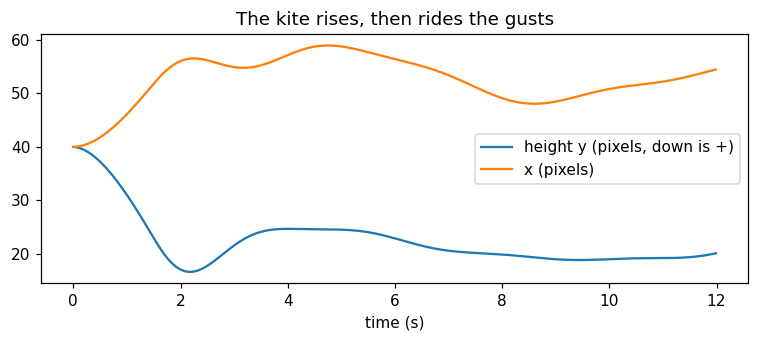

In [9]:
@dataclass
class Kite:
    anchor: tuple = (4.0, GROUND - 2.0)
    pos: np.ndarray = field(default_factory=lambda: np.array([40.0, 40.0]))
    vel: np.ndarray = field(default_factory=lambda: np.zeros(2))
    m: float = 1.0; g: float = 20.0; k: float = 6.0; L0: float = 90.0; drag: float = 1.5

    def wind(self, t):
        return np.array([10 + 4 * math.sin(0.7 * t) + 2 * math.sin(2.3 * t), -30 - 3 * math.sin(1.3 * t)])

    def forces(self, t):
        d = self.pos - np.array(self.anchor)
        L = np.linalg.norm(d)
        tension = -self.k * max(L - self.L0, 0) * d / L
        gravity = np.array([0.0, self.m * self.g])
        air = self.drag * (self.wind(t) - self.vel)
        return gravity, tension, air

    def step(self, t, dt):
        self.vel += sum(self.forces(t)) / self.m * dt
        self.pos += self.vel * dt

    def draw(self, c):
        line(c, *self.anchor, *self.pos, 15)
        x, y = self.pos
        diamond = (np.abs(X - x) / 3 + np.abs(Y - y) / 4) <= 1
        fill(c, diamond, 5); fill(c, diamond & (X > x), 6)
        for i in range(1, 6):
            put_pixel(c, x - 1 - i * 0.4, y + 3 + i + math.sin(i + x) * 0.8, 9)


kite, dt, track = Kite(), 1 / 80, []
for n in range(80 * 12):                              # 12 seconds in steps of 1/80 s
    kite.step(n * dt, dt)
    track.append(kite.pos.copy())
track = np.array(track)
g, T, A = kite.forces(12.0)
print("position after 12 s:", track[-1].round(1), " string length:", round(float(np.linalg.norm(track[-1] - kite.anchor)), 1))
print("forces now  gravity:", g.round(1), " tension:", T.round(1), " wind:", A.round(1), " total:", (g + T + A).round(1))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(np.arange(len(track)) * dt, track[:, 1], label="height y (pixels, down is +)")
ax.plot(np.arange(len(track)) * dt, track[:, 0], label="x (pixels)")
ax.set_xlabel("time (s)"); ax.legend(); ax.set_title("The kite rises, then rides the gusts"); plt.tight_layout(); plt.show()

The kite starts at (40, 40) with no speed. In the first few seconds the wind lifts it (y falls, as y counts downwards) and pushes it right until the
string goes taut; from then it hovers near the end of its string, swaying as the gusts rise and fall. The printout
checks the physics at 12 seconds: the string is a little longer than its rest length of 90, so it is stretched and
pulling; the tension points back towards the anchor (down and left, negative x and positive y); and the three forces
nearly cancel, so the total is small. A kite at rest on a taut string is exactly a balance of these three forces.

# Many agents: a flock of pigeons

The pigeons of the Badshahi courtyard wheel together. Craig Reynolds (1987) showed that a flock needs no leader:
each bird follows three local rules about the neighbours it can see (here, those within 25 pixels).

1. **Separation**: steer away from birds that are too close (closer than 5 pixels), more strongly the closer they are.
2. **Alignment**: steer towards the average heading of neighbours.
3. **Cohesion**: steer towards the average position of neighbours.

We add a fourth, a gentle pull towards a point above the mosque, so the flock stays on screen, and keep each bird's
speed between 8 and 22 pixels a second. With numpy all birds are updated at once: `d[i, j]` is the vector from bird
*j* to bird *i*, and summing over *j* adds up the effect of all neighbours.

In [10]:
@dataclass
class Flock:
    n: int = 14; seed: int = 3

    def __post_init__(self):
        rng = np.random.default_rng(self.seed)
        self.p = rng.uniform([20, 10], [140, 40], (self.n, 2))
        self.v = rng.normal(0, 8, (self.n, 2)) + [12, 0]

    def step(self, dt):
        d = self.p[:, None, :] - self.p[None, :, :]
        dist = np.linalg.norm(d, axis=2) + np.eye(self.n) * 1e9     # a bird is not its own neighbour
        near = dist < 25
        cnt = near.sum(1, keepdims=True).clip(1)
        cohesion = (near[..., None] * -d).sum(1) / cnt * 0.6
        alignment = ((near @ self.v) / cnt - self.v) * 0.5
        separation = ((dist < 5)[..., None] * d / dist[..., None] ** 2).sum(1) * 60
        home = (np.array([80, 25]) - self.p) * 0.4
        self.v += (cohesion + alignment + separation + home) * dt
        speed = np.linalg.norm(self.v, axis=1, keepdims=True)
        self.v *= np.clip(speed, 8, 22) / speed
        self.p += self.v * dt

    def spread(self):
        d = np.linalg.norm(self.p[:, None] - self.p[None], axis=2)
        return d[np.triu_indices(self.n, 1)].mean()

    def heading_agreement(self):
        u = self.v / np.linalg.norm(self.v, axis=1, keepdims=True)
        return float(np.linalg.norm(u.mean(0)))           # 1 = all fly the same way, 0 = random

    def draw(self, c, frame=0):
        for i, (x, y) in enumerate(self.p):
            dy = -1 if (frame + i) % 4 < 2 else 1           # a two-frame wing flap
            put_pixel(c, x, y, 15); put_pixel(c, x - 1, y + dy, 15); put_pixel(c, x + 1, y + dy, 15)


flock = Flock()
print(f"start: mean distance between birds {flock.spread():5.1f} px, heading agreement {flock.heading_agreement():.2f}")
for s in range(1, 201):
    flock.step(1 / 20)
    if s in (40, 200):
        print(f"{s / 20:4.0f} s: mean distance between birds {flock.spread():5.1f} px, heading agreement {flock.heading_agreement():.2f}")
inside = ((flock.p >= 0) & (flock.p < [W, H])).all(1)
print(f"birds inside the canvas: {inside.sum()} of {flock.n}; flock centre at {flock.p.mean(0).round(0)}")

start: mean distance between birds  43.1 px, heading agreement 0.73
   2 s: mean distance between birds  20.0 px, heading agreement 0.31
  10 s: mean distance between birds  13.5 px, heading agreement 0.54
birds inside the canvas: 12 of 14; flock centre at [63.  7.]


The numbers show a flock forming. At the start the birds are scattered across the sky (43 pixels apart on average)
and fairly aligned (0.73), because they were all given a push to the right. Within two seconds they have drawn
together (20 pixels apart), and after ten they are packed within about 14 pixels of each other. Heading agreement
first falls to 0.31 and then recovers to about a half: the pull towards the mosque turns the flock round, and birds on
the inside of a turn point a different way from those outside, so the flock **wheels** over the dome, as courtyard
pigeons do, rather than flying off in a line. The flock centre sits near (63, 7), above the central dome; two birds at
the top edge are briefly off the canvas (12 of 14 inside), which is harmless because `put_pixel` ignores them. No rule mentions 'the
flock': it emerges from each bird watching its neighbours, which is why this is called **emergent behaviour**.

# Putting it together: the film

The film loop now has three clocks running together: the **phase** of the day, the **physics time** of the kite and
birds, and the **frame number** for the wing flap. The kite takes four small physics steps per frame (sub-stepping)
because springs need short steps to stay stable; the birds take one.

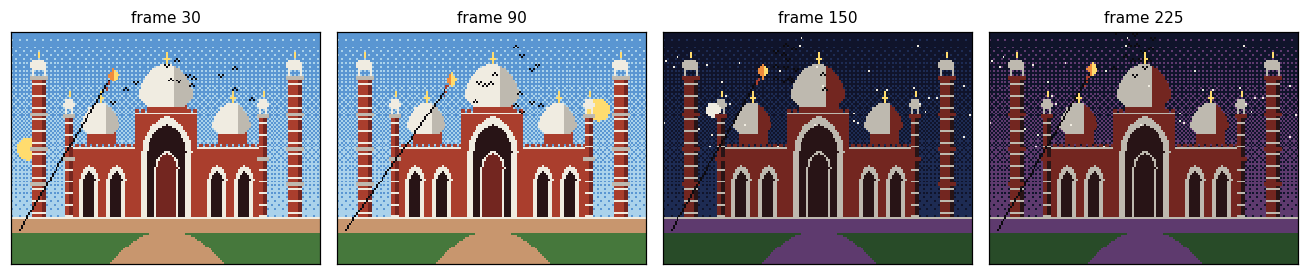

240 frames saved to data\badshahi_film.gif (0.4 MB)


In [11]:
def film(n=240, fps=20, substeps=4):
    kite, flock, frames = Kite(), Flock(), []
    dt = 1 / fps
    for f in range(n):
        for s in range(substeps):
            kite.step(f * dt + s * dt / substeps, dt / substeps)
        flock.step(dt)
        frames.append(render(-0.05 + 1.1 * f / n, extras=(lambda c, f=f: flock.draw(c, f), kite.draw)))
    return frames


frames = film()
save_gif(frames, OUT / "badshahi_film.gif")
fig, axes = plt.subplots(1, 4, figsize=(12, 2.6))
for ax, i in zip(axes, (30, 90, 150, 225)):
    show(frames[i], f"frame {i}", ax)
plt.tight_layout(); plt.show()
print(len(frames), "frames saved to", OUT / "badshahi_film.gif", f"({(OUT / 'badshahi_film.gif').stat().st_size / 1e6:.1f} MB)")

Four frames from the twelve-second film. In frame 30 it is morning (phase 0.09): the sun is low on the left, the
flock wheels over the central dome and the kite flies to the left on its taut string. In frame 90 (phase 0.36) the
sun is high in the west, on the right. Frame 150 (phase 0.64) is deep night: the building has its night colours, the
moon has risen and the birds, drawn in black, all but vanish against the sky, as real birds do. Frame 225 (phase
0.98) is the twilight before dawn, with the purple glow low in the sky; the kite still rides the wind. The whole film comes from about 250 lines of code
and no drawn images.

# What you have learned

- A picture is an array of palette indices; a palette turns them into colours, and swapping palette entries
  recolours a scene at once.
- Lines and circles are drawn with whole-number algorithms (Bresenham, midpoint); filled shapes are inside tests.
- Architecture can be written as geometry: a Mughal arch is two overlapping discs, an onion dome a width that
  varies with height.
- Dithering imitates more colours than the palette has.
- A scene is a list of components, each a class with a few numbers and a draw method; symmetry halves the work.
- Animation is drawing the scene as a function of time, many times a second.
- Motion comes from forces and integration; semi-implicit Euler keeps energy where explicit Euler explodes.
- Complex group behaviour can emerge from a few local rules.

The guide's later chapters draw the design as diagrams, rebuild the same picture in C as old `graphics.h`
programs did, and turn the film into a game you control.